# Dyslexia Handwriting Classification — Model D v4
## Multi-Level Feature Fusion + CBAM + Spatial Pyramid Pooling + MobileNetV3-Small

This notebook is based on the supplied **Model D v2 Standard Inception + SE notebook**.

### Main architectural changes in v3
- ImageNet-pretrained MobileNetV3-Small backbone
- 1-channel grayscale input with pretrained RGB weights averaged into one channel
- **Multi-level feature extraction** from early, middle and late MobileNet stages
- **Feature alignment and fusion** instead of relying only on the final feature map
- **CBAM attention**: channel attention + spatial attention
- **Spatial Pyramid Pooling (1×1, 2×2, 4×4)** to preserve multi-scale spatial information
- 1024-unit classifier with dropout
- No horizontal/vertical flips

### Training changes
- Discriminative learning rates:
  - MobileNet backbone: 1e-4
  - New fusion/attention/classifier layers: 3e-4
- AdamW + weight decay
- Label smoothing
- ReduceLROnPlateau
- Early stopping
- AMP on CUDA
- Best checkpoint selected using validation accuracy

The test set is kept completely separate from training and validation decisions.


In [1]:
# Cell 1 — Imports and GPU setup

import os
import random
import time
import copy
import json

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    ConfusionMatrixDisplay
)

from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)

print("PyTorch:", torch.__version__)
print("Torchvision:", __import__("torchvision").__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
    print("GPU memory:",
          round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
          "GB")
else:
    print("WARNING: CUDA unavailable — CPU will be used.")


PyTorch: 2.7.1+cu118
Torchvision: 0.22.1+cu118
CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
CUDA: 11.8
GPU memory: 8.0 GB


In [2]:
# Cell 2 — Configuration

DATASET_DIR = r"C:\Users\Madhu\Desktop\Dyslexia\Dataset Dyslexia_Password WanAsy321\Gambo"
TRAIN_DIR = os.path.join(DATASET_DIR, "Train")
TEST_DIR = os.path.join(DATASET_DIR, "Test")

IMG_HEIGHT = 160
IMG_WIDTH = 160

CLASS_NAMES = ["Corrected", "Normal", "Reversal"]
NUM_CLASSES = len(CLASS_NAMES)

# Training
BACKBONE_LR = 1e-4
NEW_LAYERS_LR = 3e-4
BATCH_SIZE = 32
MAX_EPOCHS = 10
WEIGHT_DECAY = 5e-4
LABEL_SMOOTHING = 0.05

# Scheduler
SCHEDULER_PATIENCE = 2
SCHEDULER_FACTOR = 0.5
MIN_LR = 1e-6

# Early stopping
EARLY_STOPPING_PATIENCE = 7

# Dataset
MAX_IMAGES_PER_CLASS_TRAIN = 25000
MAX_IMAGES_PER_CLASS_TEST = 5000
VAL_RATIO = 0.15
RANDOM_SEED = 42

# Preprocessing
USE_CLAHE = True
CLAHE_CLIP_LIMIT = 2.0
CLAHE_TILE_GRID = (8, 8)

# Augmentation
AUG_ROTATION_DEGREES = 8
AUG_TRANSLATE_PIXELS = 4
AUG_SCALE_MIN = 0.90
AUG_SCALE_MAX = 1.10
AUG_SHEAR_DEGREES = 5
AUG_BRIGHTNESS = 0.10
AUG_CONTRAST = 0.10

# Model
MODEL_V4_PRETRAINED = True
DROPOUT = 0.50

# Hybrid architecture
INCEPTION_BRANCH_KERNELS = (1, 3, 5)

# Numerical-stability/debug settings
# Start with FP32. After a stable run, USE_AMP can be enabled safely.
USE_AMP = False

NUM_WORKERS = 0
PIN_MEMORY = torch.cuda.is_available()

OUTPUT_DIR = "outputs_dyslexia_model_d_v4_debugged"
os.makedirs(OUTPUT_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True

print("Device:", DEVICE)
print("Input:", IMG_HEIGHT, "x", IMG_WIDTH, "x 1")
print("Output:", OUTPUT_DIR)


Device: cuda
Input: 160 x 160 x 1
Output: outputs_dyslexia_model_d_v4_debugged


In [3]:
# Cell 3 — Reproducibility and path checks

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(RANDOM_SEED)

for p in [DATASET_DIR, TRAIN_DIR, TEST_DIR]:
    print(("FOUND: " if os.path.isdir(p) else "MISSING: ") + p)

if not os.path.isdir(TRAIN_DIR):
    raise FileNotFoundError(f"Training directory not found: {TRAIN_DIR}")

if not os.path.isdir(TEST_DIR):
    raise FileNotFoundError(f"Test directory not found: {TEST_DIR}")


FOUND: C:\Users\Madhu\Desktop\Dyslexia\Dataset Dyslexia_Password WanAsy321\Gambo
FOUND: C:\Users\Madhu\Desktop\Dyslexia\Dataset Dyslexia_Password WanAsy321\Gambo\Train
FOUND: C:\Users\Madhu\Desktop\Dyslexia\Dataset Dyslexia_Password WanAsy321\Gambo\Test


In [4]:
# Cell 4 — Dataset file listing

def list_files_and_labels(directory, max_per_class=None, seed=42):
    rng = random.Random(seed)
    paths, labels = [], []

    for class_index, class_name in enumerate(CLASS_NAMES):
        class_dir = os.path.join(directory, class_name)

        if not os.path.isdir(class_dir):
            print("WARNING — missing class directory:", class_dir)
            continue

        files = [
            os.path.join(class_dir, f)
            for f in os.listdir(class_dir)
            if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".webp"))
        ]

        if max_per_class is not None and len(files) > max_per_class:
            files = rng.sample(files, max_per_class)

        paths.extend(files)
        labels.extend([class_index] * len(files))
        print(f"{class_name:12s}: {len(files):6d}")

    return np.array(paths), np.array(labels)

print("===== TRAINING POOL =====")
train_files, train_labels = list_files_and_labels(
    TRAIN_DIR, MAX_IMAGES_PER_CLASS_TRAIN, RANDOM_SEED
)
print("Total selected:", len(train_files))

print("\n===== TEST SET =====")
test_files, test_labels = list_files_and_labels(
    TEST_DIR, MAX_IMAGES_PER_CLASS_TEST, RANDOM_SEED
)
print("Total selected:", len(test_files))


===== TRAINING POOL =====
Corrected   :  25000
Normal      :  25000
Reversal    :  25000
Total selected: 75000

===== TEST SET =====
Corrected   :   5000
Normal      :   5000
Reversal    :   5000
Total selected: 15000


In [5]:
# Cell 5 — Stratified train / validation split

def stratified_split(files, labels, val_ratio=0.15):
    rng = np.random.RandomState(RANDOM_SEED)
    val_mask = np.zeros(len(files), dtype=bool)

    for class_index in range(NUM_CLASSES):
        indices = np.where(labels == class_index)[0]
        n_val = max(1, int(len(indices) * val_ratio))
        selected = rng.choice(indices, size=n_val, replace=False)
        val_mask[selected] = True

    return (
        files[~val_mask], labels[~val_mask],
        files[val_mask], labels[val_mask]
    )

tr_files, tr_labels, val_files, val_labels = stratified_split(
    train_files, train_labels, VAL_RATIO
)

print("Training:", len(tr_files))
print("Validation:", len(val_files))

for i, cls in enumerate(CLASS_NAMES):
    print(
        f"{cls:12s} | Train={np.sum(tr_labels == i):6d} | "
        f"Val={np.sum(val_labels == i):6d}"
    )


Training: 63750
Validation: 11250
Corrected    | Train= 21250 | Val=  3750
Normal       | Train= 21250 | Val=  3750
Reversal     | Train= 21250 | Val=  3750


## v3 preprocessing

The v2 preprocessing is retained as the baseline:

**grayscale → square padding → resize → CLAHE → normalization**

Adaptive thresholding is still excluded so that stroke-intensity information is not destroyed.

v3 adds moderate geometric and photometric augmentation during training only.

**No horizontal or vertical flipping is used**, because spatial reversal is relevant to the target classes.


In [6]:
# Cell 6 — Image preprocessing

def preprocess_image(filepath):
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)

    if img is None:
        raise ValueError(f"Could not read image: {filepath}")

    h, w = img.shape
    side = max(h, w)

    square = np.zeros((side, side), dtype=img.dtype)
    y = (side - h) // 2
    x = (side - w) // 2
    square[y:y+h, x:x+w] = img

    img = cv2.resize(
        square,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_AREA
    )

    if USE_CLAHE:
        clahe = cv2.createCLAHE(
            clipLimit=CLAHE_CLIP_LIMIT,
            tileGridSize=CLAHE_TILE_GRID
        )
        img = clahe.apply(img)

    return img.astype(np.uint8)


In [7]:
# Cell 7 — Cached dataset with safe handwriting augmentation

class DyslexiaDataset(Dataset):
    def __init__(self, filepaths, labels, training=False):
        self.filepaths = filepaths
        self.labels = labels
        self.training = training

        print(f"\nPreprocessing {len(filepaths)} images...")
        start = time.time()

        images = []
        valid_labels = []
        valid_paths = []

        for i, path in enumerate(filepaths):
            try:
                img = preprocess_image(path)
                images.append(img)
                valid_labels.append(int(labels[i]))
                valid_paths.append(path)
            except Exception as e:
                print("Skipping:", path, "|", e)

            if (i + 1) % 5000 == 0:
                print(f"  processed {i+1}/{len(filepaths)}")

        self.images = np.stack(images)
        self.labels = np.array(valid_labels, dtype=np.int64)
        self.filepaths = np.array(valid_paths)

        print(
            f"Done: {len(self.images)} images in "
            f"{time.time() - start:.1f}s"
        )

    def _augment(self, img):
        h, w = img.shape

        angle = random.uniform(-AUG_ROTATION_DEGREES, AUG_ROTATION_DEGREES)
        scale = random.uniform(AUG_SCALE_MIN, AUG_SCALE_MAX)
        tx = random.uniform(-AUG_TRANSLATE_PIXELS, AUG_TRANSLATE_PIXELS)
        ty = random.uniform(-AUG_TRANSLATE_PIXELS, AUG_TRANSLATE_PIXELS)
        shear = random.uniform(-AUG_SHEAR_DEGREES, AUG_SHEAR_DEGREES)

        center = (w / 2, h / 2)
        M = cv2.getRotationMatrix2D(center, angle, scale)

        shear_factor = np.tan(np.deg2rad(shear))
        M[0, 1] += shear_factor

        M[0, 2] += tx
        M[1, 2] += ty

        img = cv2.warpAffine(
            img,
            M,
            (w, h),
            flags=cv2.INTER_LINEAR,
            borderMode=cv2.BORDER_CONSTANT,
            borderValue=0
        )

        # Mild photometric changes.
        alpha = random.uniform(1.0 - AUG_CONTRAST, 1.0 + AUG_CONTRAST)
        beta = random.uniform(-255 * AUG_BRIGHTNESS, 255 * AUG_BRIGHTNESS)
        img = cv2.convertScaleAbs(img, alpha=alpha, beta=beta)

        return img

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img = self.images[idx].copy()

        if self.training:
            # Apply augmentation with probability 0.75.
            if random.random() < 0.75:
                img = self._augment(img)

        img = img.astype(np.float32) / 255.0
        img = (img - 0.5) / 0.5

        tensor = torch.from_numpy(img).unsqueeze(0)
        label = torch.tensor(self.labels[idx], dtype=torch.long)

        return tensor, label


In [8]:
# Cell 8 — Build datasets and DataLoaders

train_dataset = DyslexiaDataset(tr_files, tr_labels, training=True)
val_dataset = DyslexiaDataset(val_files, val_labels, training=False)
test_dataset = DyslexiaDataset(test_files, test_labels, training=False)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY
)

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))



Preprocessing 63750 images...
  processed 5000/63750
  processed 10000/63750
  processed 15000/63750
  processed 20000/63750
  processed 25000/63750
  processed 30000/63750
  processed 35000/63750
  processed 40000/63750
  processed 45000/63750
  processed 50000/63750
  processed 55000/63750
  processed 60000/63750
Done: 63750 images in 32.4s

Preprocessing 11250 images...
  processed 5000/11250
  processed 10000/11250
Done: 11250 images in 6.8s

Preprocessing 15000 images...
  processed 5000/15000
  processed 10000/15000
  processed 15000/15000
Done: 15000 images in 9.1s
Train batches: 1993
Validation batches: 352
Test batches: 469


Batch image shape: (32, 1, 160, 160)
Batch label shape: (32,)
Normalized range: -1.0 to 1.0


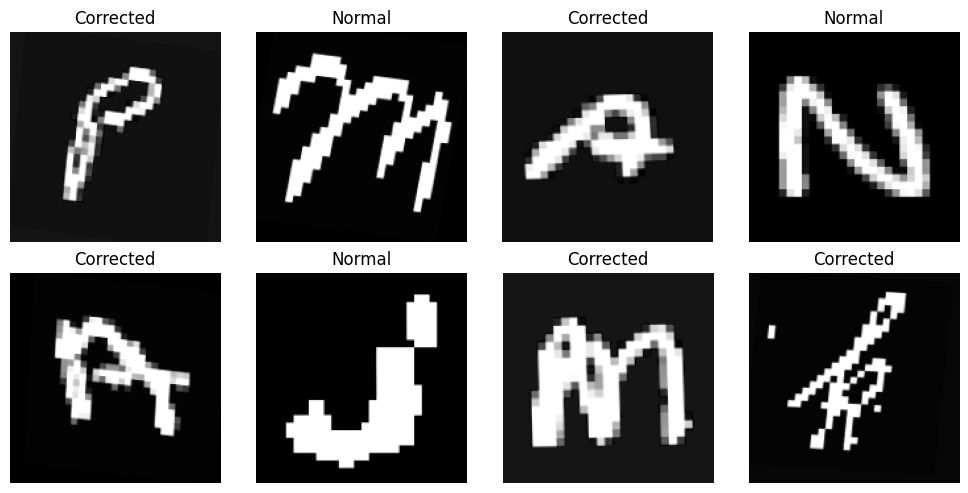

In [9]:
# Cell 9 — Dataset sanity check

images, labels = next(iter(train_loader))

print("Batch image shape:", tuple(images.shape))
print("Batch label shape:", tuple(labels.shape))
print("Normalized range:", float(images.min()), "to", float(images.max()))

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for ax, image, label in zip(axes.ravel(), images[:8], labels[:8]):
    display_image = image.squeeze(0).numpy() * 0.5 + 0.5
    ax.imshow(display_image, cmap="gray")
    ax.set_title(CLASS_NAMES[int(label)])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [10]:
# Cell 10 — GPU sanity test

if DEVICE.type == "cuda":
    x = torch.randn(
        BATCH_SIZE, 1, IMG_HEIGHT, IMG_WIDTH, device=DEVICE
    )
    torch.cuda.synchronize()
    start = time.time()
    y = x * x
    torch.cuda.synchronize()

    print("CUDA test: PASSED")
    print("GPU:", torch.cuda.get_device_name(0))
    print("Test time:", f"{time.time() - start:.4f}s")

    del x, y
    torch.cuda.empty_cache()
else:
    print("CUDA is not available.")


CUDA test: PASSED
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Test time: 0.0106s


# Model D v4 — Hybrid Inception + Multi-Level Fusion + CBAM + SPP

This version combines the major architectural ideas from Model D v2 and Model D v4.

### From Model D v2
- Standard/full-convolution Inception blocks
- 1×1, 3×3 and 5×5 branches
- SE channel recalibration
- Residual refinement
- ImageNet-pretrained MobileNetV3-Small
- 160×160 grayscale input and CLAHE
- AdamW, label smoothing, weight decay, scheduler and early stopping

### From Model D v4
- Multi-level feature extraction
- Feature alignment and fusion
- CBAM channel + spatial attention
- Spatial Pyramid Pooling: 1×1 + 2×2 + 4×4
- Discriminative learning rates
- Stronger handwriting-safe augmentation

### Final architecture

```text
160×160 grayscale
        ↓
MobileNetV3-Small
        ↓
┌────────────┬────────────┬────────────┐
│ 40-channel │ 40-channel │ 96-channel │
│   stage    │   stage    │   stage    │
└─────┬──────┴─────┬──────┴─────┬──────┘
      ↓            ↓            ↓
 Standard       Standard      Standard
 Inception      Inception     Inception
 1×1/3×3/5×5    1×1/3×3/5×5   1×1/3×3/5×5
      ↓            ↓            ↓
      └──────── Feature Alignment ────────┘
                       ↓
              Multi-Level Fusion
                       ↓
                     CBAM
              Channel + Spatial
                       ↓
             Spatial Pyramid Pooling
                 1×1 + 2×2 + 4×4
                       ↓
                 1024 classifier
                       ↓
           Corrected / Normal / Reversal
```

The key new part is that every tapped MobileNet feature is first refined by a **standard Inception + SE + residual block**, then the refined features are fused by the v3 multi-level fusion module.


In [11]:
# Cell 11 — SE and CBAM attention modules

class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 4)

        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.mlp = nn.Sequential(
            nn.Conv2d(channels, hidden, kernel_size=1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(hidden, channels, kernel_size=1, bias=False)
        )

        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = self.mlp(self.avg_pool(x))
        mx = self.mlp(self.max_pool(x))
        return x * self.sigmoid(avg + mx)


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        padding = kernel_size // 2

        self.conv = nn.Conv2d(
            2, 1,
            kernel_size=kernel_size,
            padding=padding,
            bias=False
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx, _ = torch.max(x, dim=1, keepdim=True)

        attention = torch.cat([avg, mx], dim=1)
        attention = self.sigmoid(self.conv(attention))

        return x * attention


class CBAM(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.channel = ChannelAttention(channels)
        self.spatial = SpatialAttention()

    def forward(self, x):
        x = self.channel(x)
        x = self.spatial(x)
        return x


In [12]:
# Cell 12 — Feature alignment and fusion

class FeatureAlign(nn.Module):
    def __init__(self, in_channels, out_channels=128):
        super().__init__()

        self.proj = nn.Sequential(
            nn.Conv2d(
                in_channels,
                out_channels,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.Hardswish(inplace=True)
        )

    def forward(self, x, target_size):
        x = self.proj(x)

        if x.shape[-2:] != target_size:
            x = F.interpolate(
                x,
                size=target_size,
                mode="bilinear",
                align_corners=False
            )

        return x


class MultiLevelFusion(nn.Module):
    def __init__(self, channels=(40, 40, 96), fusion_channels=128):
        super().__init__()

        self.align1 = FeatureAlign(channels[0], fusion_channels)
        self.align2 = FeatureAlign(channels[1], fusion_channels)
        self.align3 = FeatureAlign(channels[2], fusion_channels)

        self.fuse = nn.Sequential(
            nn.Conv2d(
                fusion_channels * 3,
                fusion_channels * 2,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(fusion_channels * 2),
            nn.Hardswish(inplace=True),

            nn.Conv2d(
                fusion_channels * 2,
                fusion_channels,
                kernel_size=3,
                padding=1,
                bias=False
            ),
            nn.BatchNorm2d(fusion_channels),
            nn.Hardswish(inplace=True)
        )

        self.cbam = CBAM(fusion_channels)

        self.residual = nn.Sequential(
            nn.Conv2d(
                fusion_channels * 3,
                fusion_channels,
                kernel_size=1,
                bias=False
            ),
            nn.BatchNorm2d(fusion_channels)
        )

    def forward(self, features):
        f1, f2, f3 = features

        target_size = f1.shape[-2:]

        a1 = self.align1(f1, target_size)
        a2 = self.align2(f2, target_size)
        a3 = self.align3(f3, target_size)

        merged = torch.cat([a1, a2, a3], dim=1)

        identity = self.residual(merged)
        x = self.fuse(merged)
        x = self.cbam(x)

        x = F.relu(x + identity, inplace=True)

        return x


In [13]:
# Cell 13 — Spatial Pyramid Pooling

class SpatialPyramidPooling(nn.Module):
    def __init__(self, channels, pool_sizes=(1, 2, 4)):
        super().__init__()
        self.pool_sizes = pool_sizes
        self.out_features = channels * sum(p * p for p in pool_sizes)

    def forward(self, x):
        outputs = []

        for size in self.pool_sizes:
            pooled = F.adaptive_avg_pool2d(x, (size, size))
            outputs.append(pooled.flatten(1))

        return torch.cat(outputs, dim=1)


In [14]:
# Hybrid architecture — Standard Inception + SE + Residual

class StandardInceptionBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()

        b1 = out_channels // 3
        b3 = out_channels // 3
        b5 = out_channels - b1 - b3

        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels, b1, kernel_size=1, bias=False),
            nn.BatchNorm2d(b1),
            nn.Hardswish(inplace=True)
        )

        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels, b3, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(b3),
            nn.Hardswish(inplace=True)
        )

        self.branch5 = nn.Sequential(
            nn.Conv2d(in_channels, b5, kernel_size=5, padding=2, bias=False),
            nn.BatchNorm2d(b5),
            nn.Hardswish(inplace=True)
        )

    def forward(self, x):
        return torch.cat([
            self.branch1(x),
            self.branch3(x),
            self.branch5(x)
        ], dim=1)


class InceptionSEResidual(nn.Module):
    def __init__(self, channels, ratio=8):
        super().__init__()

        self.inception = StandardInceptionBlock(channels, channels)

        reduced = max(channels // ratio, 1)

        self.pool = nn.AdaptiveAvgPool2d(1)
        self.se = nn.Sequential(
            nn.Conv2d(channels, reduced, kernel_size=1),
            nn.ReLU(inplace=True),
            nn.Conv2d(reduced, channels, kernel_size=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        identity = x

        y = self.inception(x)
        scale = self.se(self.pool(y))
        y = y * scale

        return F.hardswish(y + identity, inplace=True)


In [15]:
# Hybrid Model D v4

class ModelDV4(nn.Module):
    def __init__(self, pretrained=True, num_classes=3):
        super().__init__()

        if pretrained:
            backbone = mobilenet_v3_small(
                weights=MobileNet_V3_Small_Weights.DEFAULT
            )
        else:
            backbone = mobilenet_v3_small(weights=None)

        # Convert RGB first layer to grayscale.
        first_block = backbone.features[0]
        old_conv = first_block[0]

        new_conv = nn.Conv2d(
            1,
            old_conv.out_channels,
            kernel_size=old_conv.kernel_size,
            stride=old_conv.stride,
            padding=old_conv.padding,
            dilation=old_conv.dilation,
            groups=old_conv.groups,
            bias=False
        )

        if pretrained:
            with torch.no_grad():
                new_conv.weight.copy_(
                    old_conv.weight.mean(dim=1, keepdim=True)
                )

        first_block[0] = new_conv
        self.features = backbone.features

        # V2-style standard Inception + SE + residual refinement.
        self.inception_40_a = InceptionSEResidual(40)
        self.inception_40_b = InceptionSEResidual(40)
        self.inception_96 = InceptionSEResidual(96)

        # V3-style multi-level fusion + CBAM.
        self.fusion = MultiLevelFusion(
            channels=(40, 40, 96),
            fusion_channels=128
        )

        # V3-style spatial pyramid pooling.
        self.spp = SpatialPyramidPooling(
            channels=128,
            pool_sizes=(1, 2, 4)
        )

        spp_features = 128 * (1 + 4 + 16)

        self.classifier = nn.Sequential(
            nn.Linear(spp_features, 1024),
            nn.Hardswish(inplace=True),
            nn.Dropout(DROPOUT),
            nn.Linear(1024, num_classes)
        )

    def forward(self, x):
        f1 = f2 = f3 = None

        for i, layer in enumerate(self.features):
            x = layer(x)

            if i == 4:
                f1 = self.inception_40_a(x)

            elif i == 6:
                f2 = self.inception_40_b(x)

            elif i == 9:
                f3 = self.inception_96(x)

        fused = self.fusion([f1, f2, f3])
        pooled = self.spp(fused)

        return self.classifier(pooled)


model = ModelDV4(
    pretrained=MODEL_V4_PRETRAINED,
    num_classes=NUM_CLASSES
).to(DEVICE)

print(model)


ModelDV4(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
      (2): Hardswish()
    )
    (1): InvertedResidual(
      (block): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), groups=16, bias=False)
          (1): BatchNorm2d(16, eps=0.001, momentum=0.01, affine=True, track_running_stats=True)
          (2): ReLU(inplace=True)
        )
        (1): SqueezeExcitation(
          (avgpool): AdaptiveAvgPool2d(output_size=1)
          (fc1): Conv2d(16, 8, kernel_size=(1, 1), stride=(1, 1))
          (fc2): Conv2d(8, 16, kernel_size=(1, 1), stride=(1, 1))
          (activation): ReLU()
          (scale_activation): Hardsigmoid()
        )
        (2): Conv2dNormActivation(
          (0): Conv2d(16, 16, kernel_size=(1, 1), str

In [16]:
# Cell 15 — Parameter count and forward-pass test

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(
        p.numel() for p in model.parameters()
        if p.requires_grad
    )
    return total, trainable

total_params, trainable_params = count_parameters(model)

print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

dummy = torch.randn(
    2, 1, IMG_HEIGHT, IMG_WIDTH, device=DEVICE
)

with torch.no_grad():
    output = model(dummy)

print("Input shape:", tuple(dummy.shape))
print("Output shape:", tuple(output.shape))

assert output.shape == (2, NUM_CLASSES)

del dummy, output
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Total parameters:     4,301,739
Trainable parameters: 4,301,739
Input shape: (2, 1, 160, 160)
Output shape: (2, 3)


In [17]:
# Cell 16 — Optimizer with discriminative learning rates

backbone_params = list(model.features.parameters())
inception_params = (
    list(model.inception_40_a.parameters())
    + list(model.inception_40_b.parameters())
    + list(model.inception_96.parameters())
)
new_params = (
    inception_params
    + list(model.fusion.parameters())
    + list(model.spp.parameters())
    + list(model.classifier.parameters())
)

optimizer = optim.AdamW(
    [
        {
            "params": backbone_params,
            "lr": BACKBONE_LR
        },
        {
            "params": new_params,
            "lr": NEW_LAYERS_LR
        }
    ],
    weight_decay=WEIGHT_DECAY
)

# Make sure every trainable parameter is actually optimized.
model_param_ids = {id(p) for p in model.parameters() if p.requires_grad}
optimizer_param_ids = {id(p) for g in optimizer.param_groups for p in g["params"]}
missing_ids = model_param_ids - optimizer_param_ids
extra_ids = optimizer_param_ids - model_param_ids

print("Trainable parameters:", len(model_param_ids))
print("Optimizer parameters:", len(optimizer_param_ids))
print("Missing trainable parameters:", len(missing_ids))
print("Extra optimizer parameters:", len(extra_ids))
assert not missing_ids, "Some trainable model parameters are missing from the optimizer."
assert not extra_ids, "Optimizer contains parameters that are not trainable model parameters."

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=SCHEDULER_FACTOR,
    patience=SCHEDULER_PATIENCE,
    min_lr=MIN_LR
)

print("Backbone LR:", BACKBONE_LR)
print("New-layer LR:", NEW_LAYERS_LR)
print("Weight decay:", WEIGHT_DECAY)
print("Label smoothing:", LABEL_SMOOTHING)
print("Inception parameters included:", sum(p.numel() for p in inception_params))


Trainable parameters: 202
Optimizer parameters: 202
Missing trainable parameters: 0
Extra optimizer parameters: 0
Backbone LR: 0.0001
New-layer LR: 0.0003
Weight decay: 0.0005
Label smoothing: 0.05
Inception parameters included: 149574


## Corrected training strategy

The backbone receives the smaller learning rate, while the newly initialized Inception+SE blocks, fusion, CBAM, SPP and classifier receive the larger learning rate.

The original notebook accidentally omitted the three Inception+SE modules from the optimizer. This corrected notebook includes them and verifies that every trainable parameter is covered.

The first debug run uses FP32 (`USE_AMP=False`) and performs finite-value checks before and during training. This prevents a NaN run from silently producing an invalid checkpoint.


In [18]:
# Cell 17 — Training utilities with numerical-stability checks

def accuracy_from_logits(logits, targets):
    preds = logits.argmax(dim=1)
    return (preds == targets).float().mean().item()


def autocast_context():
    if DEVICE.type == "cuda" and USE_AMP:
        return torch.amp.autocast(device_type="cuda", dtype=torch.float16)
    return torch.autocast(device_type=DEVICE.type, enabled=False)


def run_epoch(model, loader, optimizer=None, scaler=None, epoch=None):
    training = optimizer is not None
    model.train(training)

    running_loss = 0.0
    running_correct = 0
    total = 0

    for batch_idx, (images, targets) in enumerate(loader):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        if not torch.isfinite(images).all():
            raise RuntimeError(
                f"Non-finite input detected at epoch={epoch}, batch={batch_idx}."
            )

        if training:
            optimizer.zero_grad(set_to_none=True)

        with autocast_context():
            logits = model(images)
            loss = criterion(logits, targets)

        if not torch.isfinite(logits).all():
            raise RuntimeError(
                f"Non-finite logits detected at epoch={epoch}, batch={batch_idx}. "
                "Disable AMP (USE_AMP=False) and rerun the model sanity check."
            )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite loss detected at epoch={epoch}, batch={batch_idx}. "
                "The previous notebook silently continued with NaN loss."
            )

        if training:
            if scaler is not None and scaler.is_enabled():
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
            else:
                loss.backward()

            # Detect exploding/non-finite gradients before changing weights.
            bad_grad = None
            for name, param in model.named_parameters():
                if param.grad is not None and not torch.isfinite(param.grad).all():
                    bad_grad = name
                    break
            if bad_grad is not None:
                raise RuntimeError(
                    f"Non-finite gradient detected at epoch={epoch}, batch={batch_idx}, "
                    f"parameter={bad_grad}."
                )

            torch.nn.utils.clip_grad_norm_(
                model.parameters(), max_norm=1.0
            )

            if scaler is not None and scaler.is_enabled():
                scaler.step(optimizer)
                scaler.update()
            else:
                optimizer.step()

        batch_size = targets.size(0)
        running_loss += loss.detach().item() * batch_size
        running_correct += (
            logits.argmax(dim=1) == targets
        ).sum().item()
        total += batch_size

    return running_loss / total, running_correct / total


@torch.no_grad()
def evaluate(model, loader):
    model.eval()

    running_loss = 0.0
    running_correct = 0
    total = 0

    all_targets = []
    all_preds = []

    for batch_idx, (images, targets) in enumerate(loader):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)

        with autocast_context():
            logits = model(images)
            loss = criterion(logits, targets)

        if not torch.isfinite(logits).all() or not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite validation output at batch={batch_idx}."
            )

        preds = logits.argmax(dim=1)

        batch_size = targets.size(0)
        running_loss += loss.item() * batch_size
        running_correct += (preds == targets).sum().item()
        total += batch_size

        all_targets.extend(targets.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

    return (
        running_loss / total,
        running_correct / total,
        np.array(all_targets),
        np.array(all_preds)
    )


In [19]:
# Cell 18 — Full training

# FP32 is the default for the first debugged run.
# If USE_AMP=True, use the modern GradScaler API.
scaler = (
    torch.amp.GradScaler("cuda", enabled=True)
    if DEVICE.type == "cuda" and USE_AMP
    else None
)

# One-batch numerical preflight before spending time on a full epoch.
model.eval()
probe_images, probe_targets = next(iter(train_loader))
probe_images = probe_images.to(DEVICE)
probe_targets = probe_targets.to(DEVICE)
with torch.no_grad():
    with autocast_context():
        probe_logits = model(probe_images)
        probe_loss = criterion(probe_logits, probe_targets)
print("Preflight input finite:", torch.isfinite(probe_images).all().item())
print("Preflight logits finite:", torch.isfinite(probe_logits).all().item())
print("Preflight loss finite:", torch.isfinite(probe_loss).item())
print("Preflight loss:", float(probe_loss))
assert torch.isfinite(probe_images).all()
assert torch.isfinite(probe_logits).all()
assert torch.isfinite(probe_loss)
del probe_images, probe_targets, probe_logits, probe_loss

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "val_balanced_acc": [],
    "lr_backbone": [],
    "lr_new_layers": []
}

best_val_acc = -1.0
best_state = None
best_epoch = -1
epochs_without_improvement = 0

checkpoint_path = os.path.join(
    OUTPUT_DIR,
    "model_d_v4_best.pth"
)

for epoch in range(1, MAX_EPOCHS + 1):
    start = time.time()

    train_loss, train_acc = run_epoch(
        model,
        train_loader,
        optimizer=optimizer,
        scaler=scaler,
        epoch=epoch
    )

    val_loss, val_acc, val_targets, val_preds = evaluate(
        model,
        val_loader
    )

    val_bal_acc = balanced_accuracy_score(
        val_targets,
        val_preds
    )

    scheduler.step(val_acc)

    current_lr_backbone = optimizer.param_groups[0]["lr"]
    current_lr_new = optimizer.param_groups[1]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["val_balanced_acc"].append(val_bal_acc)
    history["lr_backbone"].append(current_lr_backbone)
    history["lr_new_layers"].append(current_lr_new)

    elapsed = time.time() - start

    print(
        f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.4f} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.4f} | "
        f"Val Bal Acc {val_bal_acc:.4f} | "
        f"LR {current_lr_backbone:.2e}/{current_lr_new:.2e} | "
        f"{elapsed:.1f}s"
    )

    if not np.isfinite(val_acc):
        raise RuntimeError("Validation accuracy became non-finite; stopping before saving a bad checkpoint.")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch
        best_state = copy.deepcopy(model.state_dict())

        torch.save(
            {
                "model_state_dict": best_state,
                "best_val_accuracy": best_val_acc,
                "best_epoch": best_epoch,
                "class_names": CLASS_NAMES,
                "img_size": (IMG_HEIGHT, IMG_WIDTH)
            },
            checkpoint_path
        )

        epochs_without_improvement = 0
        print("  -> Best validation model saved.")
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping triggered.")
        break

print("\nBest validation accuracy:", best_val_acc)
print("Best epoch:", best_epoch)


Preflight input finite: True
Preflight logits finite: True
Preflight loss finite: True
Preflight loss: 1.09868586063385
Epoch 01/10 | Train Loss 0.3551 | Train Acc 0.9181 | Val Loss 0.9175 | Val Acc 0.6636 | Val Bal Acc 0.6636 | LR 1.00e-04/3.00e-04 | 111.9s
  -> Best validation model saved.
Epoch 02/10 | Train Loss 0.2604 | Train Acc 0.9624 | Val Loss 0.2410 | Val Acc 0.9715 | Val Bal Acc 0.9715 | LR 1.00e-04/3.00e-04 | 108.7s
  -> Best validation model saved.
Epoch 03/10 | Train Loss 0.2369 | Train Acc 0.9726 | Val Loss 0.2416 | Val Acc 0.9692 | Val Bal Acc 0.9692 | LR 1.00e-04/3.00e-04 | 111.0s
Epoch 04/10 | Train Loss 0.2242 | Train Acc 0.9775 | Val Loss 0.7035 | Val Acc 0.7437 | Val Bal Acc 0.7437 | LR 1.00e-04/3.00e-04 | 112.3s
Epoch 05/10 | Train Loss 0.2148 | Train Acc 0.9809 | Val Loss 0.1944 | Val Acc 0.9892 | Val Bal Acc 0.9892 | LR 1.00e-04/3.00e-04 | 115.7s
  -> Best validation model saved.
Epoch 06/10 | Train Loss 0.2098 | Train Acc 0.9831 | Val Loss 0.1985 | Val Acc 0.98

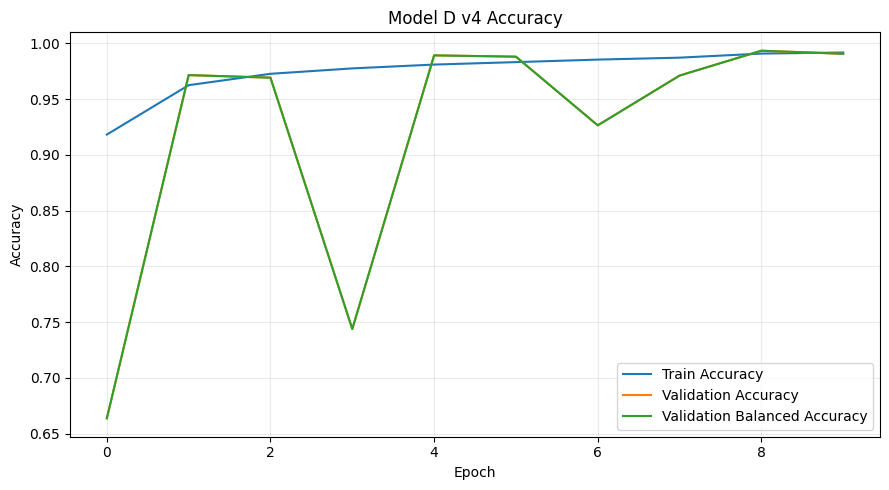

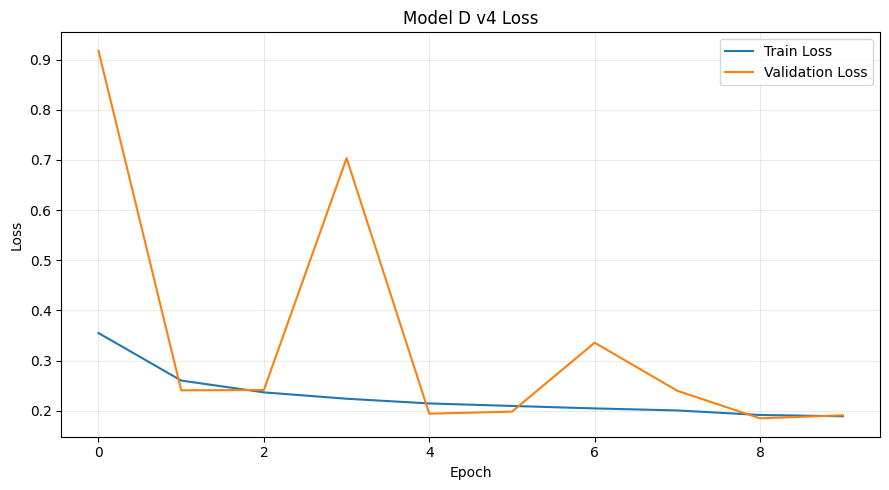

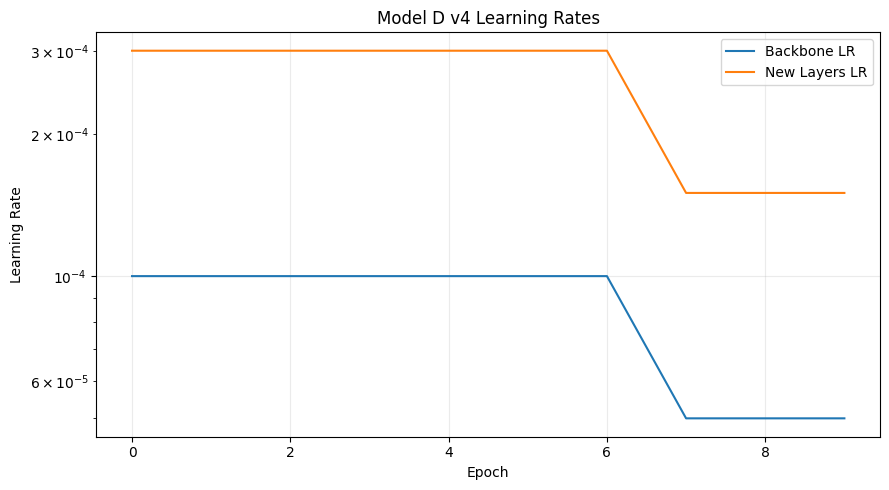

In [20]:
# Cell 19 — Training curves

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(history["train_acc"], label="Train Accuracy")
ax.plot(history["val_acc"], label="Validation Accuracy")
ax.plot(history["val_balanced_acc"], label="Validation Balanced Accuracy")
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
ax.set_title("Model D v4 Accuracy")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "model_d_v4_accuracy.png"),
    dpi=150
)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(history["train_loss"], label="Train Loss")
ax.plot(history["val_loss"], label="Validation Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
ax.set_title("Model D v4 Loss")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "model_d_v4_loss.png"),
    dpi=150
)
plt.show()

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(history["lr_backbone"], label="Backbone LR")
ax.plot(history["lr_new_layers"], label="New Layers LR")
ax.set_xlabel("Epoch")
ax.set_ylabel("Learning Rate")
ax.set_yscale("log")
ax.set_title("Model D v4 Learning Rates")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(
    os.path.join(OUTPUT_DIR, "model_d_v4_learning_rate.png"),
    dpi=150
)
plt.show()


In [21]:
# Cell 20 — Load best checkpoint and evaluate on test set

if os.path.isfile(checkpoint_path):
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE
    )
    model.load_state_dict(checkpoint["model_state_dict"])

    print(
        "Loaded best checkpoint from epoch:",
        checkpoint["best_epoch"]
    )

test_loss, test_acc, test_targets, test_preds = evaluate(
    model,
    test_loader
)

test_bal_acc = balanced_accuracy_score(
    test_targets,
    test_preds
)

print(f"Test Loss:              {test_loss:.4f}")
print(f"Test Accuracy:          {test_acc:.4f}")
print(f"Test Balanced Accuracy: {test_bal_acc:.4f}")


Loaded best checkpoint from epoch: 9
Test Loss:              0.3812
Test Accuracy:          0.9253
Test Balanced Accuracy: 0.9253


In [22]:
# Cell 21 — Classification report

report = classification_report(
    test_targets,
    test_preds,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
)

print(report)

report_dict = classification_report(
    test_targets,
    test_preds,
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0
)

print("\nReversal metrics:")
print(
    "Precision:",
    f"{report_dict['Reversal']['precision']:.4f}"
)
print(
    "Recall:",
    f"{report_dict['Reversal']['recall']:.4f}"
)
print(
    "F1:",
    f"{report_dict['Reversal']['f1-score']:.4f}"
)

              precision    recall  f1-score   support

   Corrected     0.9705    0.9336    0.9517      5000
      Normal     0.8690    0.9184    0.8930      5000
    Reversal     0.9417    0.9240    0.9328      5000

    accuracy                         0.9253     15000
   macro avg     0.9271    0.9253    0.9258     15000
weighted avg     0.9271    0.9253    0.9258     15000


Reversal metrics:
Precision: 0.9417
Recall: 0.9240
F1: 0.9328


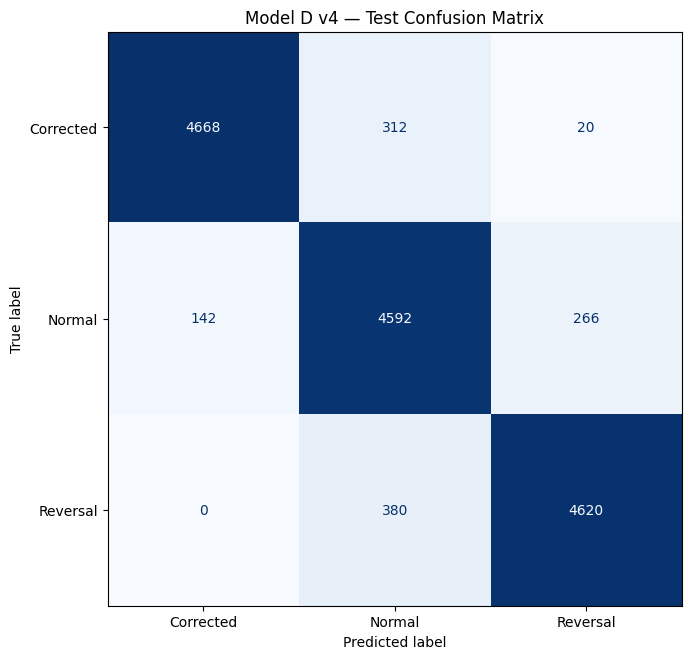

Confusion matrix:
[[4668  312   20]
 [ 142 4592  266]
 [   0  380 4620]]


In [23]:
# Cell 22 — Confusion matrix

cm = confusion_matrix(
    test_targets,
    test_preds
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(7, 7))
disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Model D v4 — Test Confusion Matrix")
plt.tight_layout()

cm_path = os.path.join(
    OUTPUT_DIR,
    "model_d_v4_confusion_matrix.png"
)

plt.savefig(cm_path, dpi=150)
plt.show()

print("Confusion matrix:")
print(cm)


In [24]:
# Cell 23 — Save results

results = {
    "model": "Model D v4 — Multi-Level Fusion + CBAM + SPP + MobileNetV3-Small",
    "best_epoch": best_epoch,
    "best_validation_accuracy": best_val_acc,
    "test_accuracy": test_acc,
    "test_balanced_accuracy": test_bal_acc,
    "test_loss": test_loss,
    "total_parameters": total_params,
    "trainable_parameters": trainable_params,
    "input_height": IMG_HEIGHT,
    "input_width": IMG_WIDTH,
    "backbone_lr": BACKBONE_LR,
    "new_layers_lr": NEW_LAYERS_LR,
    "weight_decay": WEIGHT_DECAY,
    "label_smoothing": LABEL_SMOOTHING
}

for cls in CLASS_NAMES:
    results[f"{cls}_precision"] = report_dict[cls]["precision"]
    results[f"{cls}_recall"] = report_dict[cls]["recall"]
    results[f"{cls}_f1"] = report_dict[cls]["f1-score"]

results_df = pd.DataFrame([results])

results_csv = os.path.join(
    OUTPUT_DIR,
    "model_d_v4_results.csv"
)

results_df.to_csv(results_csv, index=False)

print(results_df.T)
print("\nSaved:", results_csv)


                                                                          0
model                     Model D v4 — Multi-Level Fusion + CBAM + SPP +...
best_epoch                                                                9
best_validation_accuracy                                           0.993333
test_accuracy                                                      0.925333
test_balanced_accuracy                                             0.925333
test_loss                                                          0.381236
total_parameters                                                    4301739
trainable_parameters                                                4301739
input_height                                                            160
input_width                                                             160
backbone_lr                                                          0.0001
new_layers_lr                                                        0.0003
weight_decay

# Model D v4 Summary

### Architecture

```text
1 × 160 × 160
      ↓
MobileNetV3-Small
      ↓
┌──────────────┬──────────────┬──────────────┐
│ Early 40 ch  │ Middle 40 ch │ Late 96 ch  │
└──────┬───────┴──────┬───────┴──────┬───────┘
       ↓              ↓              ↓
       └──────── Feature Fusion ─────┘
                     ↓
                    CBAM
             Channel + Spatial
                     ↓
             Residual refinement
                     ↓
       Spatial Pyramid Pooling
             1×1 + 2×2 + 4×4
                     ↓
              1024 FC + Dropout
                     ↓
          Corrected / Normal / Reversal
```

### Main differences from Model D v2

| Component | Model D v2 | Model D v4 |
|---|---|---|
| Backbone | MobileNetV3-Small | MobileNetV3-Small |
| Input | 160×160 grayscale | 160×160 grayscale |
| Feature usage | Mainly final representation | **Early + middle + late fusion** |
| Attention | SE | **CBAM** |
| Spatial pooling | Global average | **1×1 + 2×2 + 4×4 SPP** |
| Learning rate | Same LR | **Discriminative LR** |
| Augmentation | Rotation + translation | **Rotation + translation + scale + shear + photometric variation** |
| Label smoothing | 0.05 | 0.05 |
| Weight decay | 5e-4 | 5e-4 |
| Scheduler | ReduceLROnPlateau | ReduceLROnPlateau |
| Early stopping | 6 | 7 |
| Test set used for decisions | No | No |

### Important experiment

If validation accuracy remains near 99% while test accuracy remains near 88%, the next investigation should be **writer-independent/group-based splitting** if the dataset contains multiple samples from the same writer. An architectural change alone cannot guarantee that kind of generalization gap will disappear.


# Model D v4 Summary

### Architecture

```text
                    1 × 160 × 160
                           ↓
              ┌──────────────────────┐
              │  MobileNetV3-Small   │
              │   Feature Backbone   │
              └──────────┬───────────┘
                         ↓
              Multi-Level Feature Extraction
                         ↓
        ┌────────────────┼────────────────┐
        ↓                ↓                ↓
   Early Feature     Middle Feature    Late Feature
      40 ch              40 ch             96 ch
        ↓                ↓                ↓
 ┌─────────────┐  ┌─────────────┐  ┌─────────────┐
 │  Inception  │  │  Inception  │  │  Inception  │
 │  1×1 Branch │  │  1×1 Branch │  │  1×1 Branch │
 │  3×3 Branch │  │  3×3 Branch │  │  3×3 Branch │
 │  5×5 Branch │  │  5×5 Branch │  │  5×5 Branch │
 └──────┬──────┘  └──────┬──────┘  └──────┬──────┘
        ↓                ↓                ↓
       SE               SE               SE
        ↓                ↓                ↓
   Residual         Residual         Residual
   Connection       Connection       Connection
        ↓                ↓                ↓
        └────────────────┼────────────────┘
                         ↓
              Feature Alignment
                  1×1 Conv
                     ↓
              Multi-Level Fusion
                     ↓
                    CBAM
             ┌───────┴────────┐
             ↓                ↓
      Channel Attention   Spatial Attention
             └───────┬────────┘
                     ↓
             Residual Refinement
                     ↓
       Spatial Pyramid Pooling
        ┌────────┬────────┬────────┐
        ↓        ↓        ↓
       1×1      2×2      4×4
        └────────┼────────┘
                 ↓
              Flatten
                 ↓
          Fully Connected
             1024 Units
                 ↓
             Hardswish
                 ↓
              Dropout
                 ↓
          Fully Connected
                 ↓
     Corrected / Normal / Reversal


### VT2

```markdown
# VT2 Summary

### Architecture

```text
                    3 × 224 × 224
                           ↓
                  Image Preprocessing
                           ↓
                 Split into 16×16 Patches
                           ↓
                  Patch Embedding
                           ↓
              Add Positional Information
                           ↓
                  Transformer Encoder
                           ↓
        ┌──────────────────────────────────┐
        │        Transformer Block         │
        │                                  │
        │   Multi-Head Self-Attention      │
        │               ↓                  │
        │      Add & Layer Normalization   │
        │               ↓                  │
        │     Feed-Forward Network (MLP)   │
        │               ↓                  │
        │      Add & Layer Normalization   │
        └────────────────┬─────────────────┘
                         ↓
                Repeated Transformer
                     Encoder Blocks
                         ↓
                  Class Representation
                         ↓
                Classification Head
                         ↓
             ┌─────────────────────┐
             │      3 Classes      │
             └─────────────────────┘
                         ↓
             Corrected / Normal /
                    Reversal